In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import hvplot.xarray
# from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
from scipy.optimize import curve_fit

[ 8.26795396e-14  4.00292134e-14 -1.78406381e-09 -2.50841622e-09
  4.67437798e-06  1.82610922e-05 -1.28733196e-01 -1.78388874e-02]


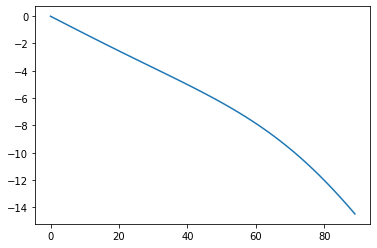

In [7]:
calib_dir = 'C:/Users/RalphGroup/Documents/group_code/daedalus_control/calibrations/'
radial_polar_coeff= np.loadtxt(calib_dir + 'daedalus_radial_polar_calib.csv', delimiter=',')
radial_polar_calib = np.poly1d(radial_polar_coeff)
theta = np.arange(0, 90, 1)
plt.plot(theta, radial_polar_calib(theta))
print(radial_polar_coeff)

In [12]:
measured = pd.read_csv('./2024-07-17/RadialPositionVersusField_daedalus_radialPolar_calib_A000.0_2024-07-17_5.csv', comment = '#', index_col = 'theta')
ds = xr.Dataset(measured)
ds = ds.where(ds.R < 14, drop=True)

[ 1.36999919e-09 -4.36273456e-07  3.06305336e-05 -6.13441870e-04
 -1.21427680e-01 -1.09075274e-02]


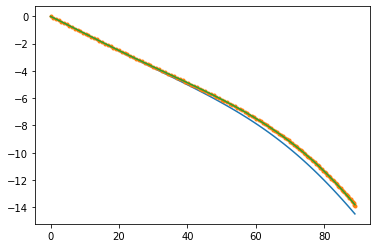

In [22]:
theta = np.arange(0, 90, 1)
plt.plot(theta, radial_polar_calib(theta))
plt.plot(-ds['theta'], -ds['R'], '.')

radial_polar_coeff_new = np.polyfit(-ds['theta'], -ds['R'], 5)
print(radial_polar_coeff_new)
radial_polar_calib_new = np.poly1d(radial_polar_coeff_new)
plt.plot(theta, radial_polar_calib_new(theta))